# Module 07, Part 4: Latent space structure, interpolation and conditioning

This notebook is the runnable companion to Part 4 of the Module 07 learning content.
It checks, with code:

1. What the two-dimensional latent space of a VAE looks like, compared with an autoencoder's.
2. Whether walking between two codes gives a better path than blending the two images, measured, not assumed.
3. What each latent dimension does when you move along it.
4. How a conditional VAE lets you ask for a particular digit, and what is left for the code to describe.

The classifier used to judge generated images is a small network trained on real digits, defined in Part 5's metrics file. It reaches about 97% accuracy on real test images.

In [1]:
import math
import warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import linalg
from sklearn.datasets import load_digits
warnings.filterwarnings("ignore")
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
class AE(nn.Module):
    """Encoder, bottleneck of size d_latent, decoder. With linear=True there are no hidden layers or activations."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, linear=False):
        super().__init__()
        if linear:
            self.enc = nn.Linear(d_in, d_latent)
            self.dec = nn.Linear(d_latent, d_in)
        else:
            self.enc = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_latent))
            self.dec = nn.Sequential(nn.Linear(d_latent, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        return self.decode(self.encode(x))


def train_ae(model, X, epochs=300, lr=2e-3, batch_size=64, noise=0.0, seed=0):
    """Train with mean squared error. noise > 0 corrupts the input but still rebuilds the clean image (a denoising autoencoder).
    Returns the mean loss of each epoch."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for _ in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        total = 0.0
        for i in range(0, len(X), batch_size):
            xb = X[perm[i:i + batch_size]]
            xin = xb + noise * torch.randn(xb.shape, generator=g) if noise > 0 else xb
            loss = ((model(xin) - xb) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        hist.append(total / len(X))
    return hist


@torch.no_grad()
def reconstruction_mse(model, X):
    return ((model(X) - X) ** 2).mean().item()


def pca_mse(X_train, X_eval, k):
    """Mean squared error of rebuilding X_eval from the top k principal components of X_train."""
    X_train = X_train.numpy().astype(np.float64)
    X_eval = X_eval.numpy().astype(np.float64)
    mu = X_train.mean(0)
    _, _, Vt = np.linalg.svd(X_train - mu, full_matrices=False)
    P = Vt[:k]
    rec = (X_eval - mu) @ P.T @ P + mu
    return float(((rec - X_eval) ** 2).mean())

In [4]:
class VAE(nn.Module):
    """Gaussian encoder q(z|x), Bernoulli-on-intensity decoder p(x|z). With n_classes > 0 both networks also see a one-hot label."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, n_classes=0):
        super().__init__()
        self.d_latent, self.n_classes = d_latent, n_classes
        self.enc = nn.Sequential(nn.Linear(d_in + n_classes, d_hidden), nn.ReLU())
        self.mu = nn.Linear(d_hidden, d_latent)
        self.logvar = nn.Linear(d_hidden, d_latent)
        self.dec = nn.Sequential(nn.Linear(d_latent + n_classes, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, c=None):
        """Returns logits; apply a sigmoid to get pixel intensities."""
        return self.dec(z if c is None else torch.cat([z, c], 1))

    @staticmethod
    def reparameterize(mu, logvar, generator=None):
        eps = torch.randn(mu.shape, generator=generator)
        return mu + torch.exp(0.5 * logvar) * eps

    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, c), mu, logvar


def kl_to_standard_normal(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) summed over latent dimensions, one value per example."""
    return 0.5 * (mu ** 2 + torch.exp(logvar) - 1.0 - logvar).sum(1)


def reconstruction_nll(logits, x):
    """Bernoulli negative log-likelihood of the pixel intensities, summed over pixels, one value per example."""
    return F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)


def elbo_terms(model, x, c=None):
    """One-sample estimate of the two terms of the negative ELBO, each averaged over the batch."""
    logits, mu, logvar = model(x, c)
    return reconstruction_nll(logits, x).mean(), kl_to_standard_normal(mu, logvar).mean()


def train_vae(model, X, y_onehot=None, epochs=200, lr=2e-3, batch_size=64, beta=1.0, anneal_epochs=0, seed=0):
    """Minimize recon + beta * KL. With anneal_epochs > 0, beta rises linearly from 0 to its final value over that many epochs.
    Returns a list of (reconstruction, KL) epoch averages."""
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        b = beta * min(1.0, ep / anneal_epochs) if anneal_epochs > 0 else beta
        perm = torch.randperm(len(X), generator=g)
        sr = sk = 0.0
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            xb = X[idx]
            cb = y_onehot[idx] if y_onehot is not None else None
            rec, kl = elbo_terms(model, xb, cb)
            loss = rec + b * kl
            opt.zero_grad()
            loss.backward()
            opt.step()
            sr += rec.item() * len(xb)
            sk += kl.item() * len(xb)
        hist.append((sr / len(X), sk / len(X)))
    return hist


@torch.no_grad()
def evaluate_terms(model, X, c=None, repeats=10, seed=0):
    """Average (reconstruction, KL) over the set, using several draws of z per example."""
    torch.manual_seed(seed)
    r = k = 0.0
    for _ in range(repeats):
        rec, kl = elbo_terms(model, X, c)
        r += rec.item() / repeats
        k += kl.item() / repeats
    return r, k


@torch.no_grad()
def iwae_bound(model, x, K=1, seed=0):
    """Importance-weighted estimate of log p(x) per example, using q(z|x) as the proposal and K samples.
    K = 1 is the ELBO. As K grows the bound tightens toward log p(x)."""
    torch.manual_seed(seed)
    mu, logvar = model.encode(x)
    std = torch.exp(0.5 * logvar)
    logw = []
    for _ in range(K):
        z = mu + std * torch.randn_like(std)
        logits = model.decode(z)
        log_px_z = -reconstruction_nll(logits, x)
        log_pz = -0.5 * (z ** 2 + math.log(2 * math.pi)).sum(1)
        log_qz = -0.5 * (((z - mu) / std) ** 2 + math.log(2 * math.pi) + logvar).sum(1)
        logw.append(log_px_z + log_pz - log_qz)
    logw = torch.stack(logw, 0)
    return torch.logsumexp(logw, 0) - math.log(K)


@torch.no_grad()
def active_units(model, X, threshold=0.01):
    """Number of latent dimensions whose posterior mean varies across the data by more than the threshold (variance)."""
    mu, _ = model.encode(X)
    return int((mu.var(0) > threshold).sum().item())

In [5]:
@torch.no_grad()
def interpolate_latent(model, x1, x2, steps=8):
    """Decode points on the straight line between the latent means of two images (autoencoder or VAE)."""
    if hasattr(model, "mu"):
        z1, z2 = model.encode(x1[None])[0], model.encode(x2[None])[0]
        dec = lambda z: torch.sigmoid(model.decode(z))
    else:
        z1, z2 = model.encode(x1[None]), model.encode(x2[None])
        dec = lambda z: model.decode(z)
    ts = torch.linspace(0, 1, steps)[:, None]
    z = (1 - ts) * z1 + ts * z2
    return dec(z)


def interpolate_pixels(x1, x2, steps=8):
    """The baseline: a straight line between the two images in pixel space."""
    ts = torch.linspace(0, 1, steps)[:, None]
    return (1 - ts) * x1[None] + ts * x2[None]


@torch.no_grad()
def decode_grid(model, lim=2.5, n=12, vae=True):
    """Decode an n by n grid of a two-dimensional latent space. Returns an array of shape (n, n, 8, 8), top row = largest z2."""
    zs = torch.linspace(-lim, lim, n)
    zz = torch.stack(torch.meshgrid(zs, zs.flip(0), indexing="xy"), -1).reshape(-1, 2)
    out = model.decode(zz)
    out = torch.sigmoid(out) if vae else out
    return out.reshape(n, n, 8, 8)


@torch.no_grad()
def sample_prior(model, n, seed=0):
    """Draw z from the standard normal prior and decode. Intensities in [0, 1]."""
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, model.d_latent if hasattr(model, "d_latent") else model.dec[0].in_features, generator=g)
    out = model.decode(z)
    return torch.sigmoid(out) if hasattr(model, "mu") else out


@torch.no_grad()
def sample_conditional(model, digit, n, seed=0):
    """Conditional VAE: draw z from the prior and decode with the one-hot label of the requested digit."""
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, model.d_latent, generator=g)
    c = torch.nn.functional.one_hot(torch.full((n,), digit), model.n_classes).float()
    return torch.sigmoid(model.decode(z, c))

In [6]:
class FeatureNet(nn.Module):
    """A small classifier trained on real digits. Its hidden layer plays the role Inception plays in FID."""

    def __init__(self, d_in=64, d_feat=32):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, d_feat), nn.ReLU())
        self.head = nn.Linear(d_feat, 10)

    def features(self, x):
        return self.body(x)

    def forward(self, x):
        return self.head(self.body(x))


def train_feature_net(X, y, epochs=60, seed=0):
    torch.manual_seed(seed)
    net = FeatureNet()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]
            loss = nn.functional.cross_entropy(net(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net


@torch.no_grad()
def get_features(net, X):
    return net.features(X).numpy().astype(np.float64)


def frechet_distance(fa, fb):
    """Frechet distance between Gaussians fitted to two sets of features (the quantity behind FID)."""
    mu_a, mu_b = fa.mean(0), fb.mean(0)
    eps = 1e-6 * np.eye(fa.shape[1])
    ca, cb = np.cov(fa, rowvar=False) + eps, np.cov(fb, rowvar=False) + eps
    covmean = linalg.sqrtm(ca @ cb)
    covmean = covmean.real
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca) + np.trace(cb) - 2 * np.trace(covmean))


def _knn_radius(F, k):
    d = np.linalg.norm(F[:, None] - F[None], axis=-1)
    return np.sort(d, axis=1)[:, k]


def precision_recall(real, fake, k=3):
    """Precision: share of generated points that land inside the real data's neighbourhood.
    Recall: share of real points that land inside the generated data's neighbourhood. (k-nearest-neighbour balls.)"""
    r_real, r_fake = _knn_radius(real, k), _knn_radius(fake, k)
    d = np.linalg.norm(fake[:, None] - real[None], axis=-1)
    precision = float((d <= r_real[None]).any(1).mean())
    recall = float((d.T <= r_fake[None]).any(1).mean())
    return precision, recall


def nearest_train_distance(samples, train):
    """Pixel-space distance from each generated image to its nearest training image. Near zero means copying."""
    d = torch.cdist(samples, train)
    return d.min(1).values

In [7]:
Xtr, ytr, Xte, yte = load_data()
net = train_feature_net(Xtr, ytr)
with torch.no_grad():
    print("classifier accuracy on real test images:", round((net(Xte).argmax(1) == yte).float().mean().item(), 3))
def show_rows(rows, labels, title=None):
    nrows, ncols = len(rows), len(rows[0])
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 0.9, nrows * 0.95 + 0.3))
    for i in range(nrows):
        for j in range(ncols):
            axes[i, j].imshow(np.asarray(rows[i][j]).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); axes[i, j].axis("off")
        axes[i, 0].set_title(labels[i], fontsize=8, loc="left")
    if title: fig.suptitle(title, y=1.0, fontsize=10)
    plt.show()

classifier accuracy on real test images: 0.972


## 1. A two-dimensional latent space

With a code of size 2 the whole latent space can be drawn. The left plot shows the codes of the test digits for an autoencoder and for a VAE, and the VAE's
decoded grid shows what each region of the plane produces.

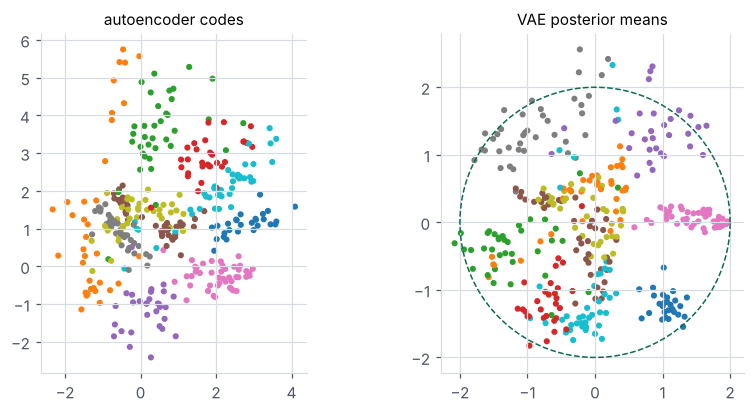

per-dimension mean / std of the codes
  autoencoder: [0.77 1.29] [1.38 1.53]
  VAE        : [-0.02 -0.03] [0.94 0.98]


In [8]:
torch.manual_seed(0)
ae2 = AE(d_latent=2); train_ae(ae2, Xtr, epochs=300)
vae2 = VAE(d_latent=2); train_vae(vae2, Xtr, epochs=200, beta=1.0)
with torch.no_grad():
    z_ae = ae2.encode(Xte).numpy()
    z_vae = vae2.encode(Xte)[0].numpy()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, z, name in zip(axes, (z_ae, z_vae), ("autoencoder codes", "VAE posterior means")):
    sc = ax.scatter(z[:, 0], z[:, 1], c=yte.numpy(), cmap="tab10", s=9)
    ax.set_title(name, fontsize=10); ax.set_aspect("equal")
th = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(2 * np.cos(th), 2 * np.sin(th), color=GREEN, lw=1, ls="--")
plt.show()
print("per-dimension mean / std of the codes")
print("  autoencoder:", np.round(z_ae.mean(0), 2), np.round(z_ae.std(0), 2))
print("  VAE        :", np.round(z_vae.mean(0), 2), np.round(z_vae.std(0), 2))

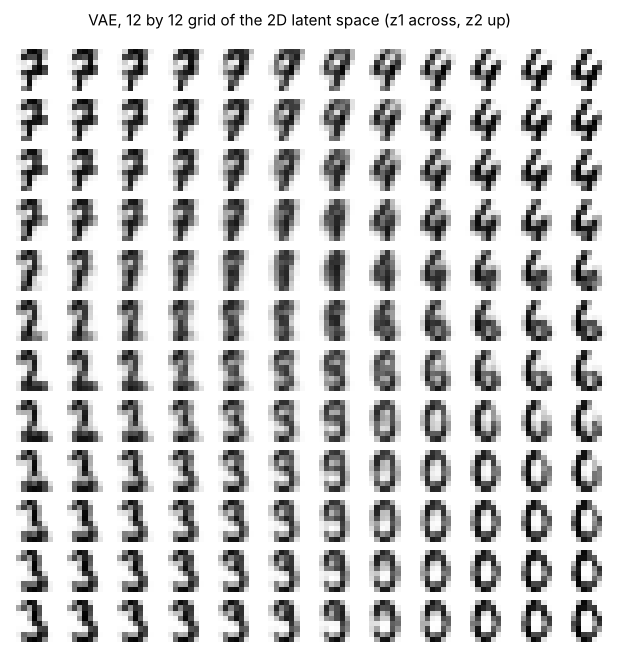

In [9]:
grid = decode_grid(vae2, lim=2.5, n=12, vae=True)
fig, axes = plt.subplots(12, 12, figsize=(7, 7))
for i in range(12):
    for j in range(12):
        axes[i, j].imshow(grid[i, j], cmap="gray_r", vmin=0, vmax=1); axes[i, j].axis("off")
plt.suptitle("VAE, 12 by 12 grid of the 2D latent space (z1 across, z2 up)", y=0.93, fontsize=10); plt.show()

The VAE's codes are centred on zero with a spread close to 1 in each direction, so the prior's region is the region the data occupy, and the decoded grid changes
smoothly from one digit to another across the plane. Nothing in the autoencoder's training asked for either property. A two-dimensional code is also very small for
ten digits, so neighbouring regions blend, and some digits share territory.

## 2. Interpolation: measured, not assumed

A popular claim is that walking in latent space between two images gives a more natural path than cross-fading the pixels. The pictures below show the paths for three
pairs of digits.

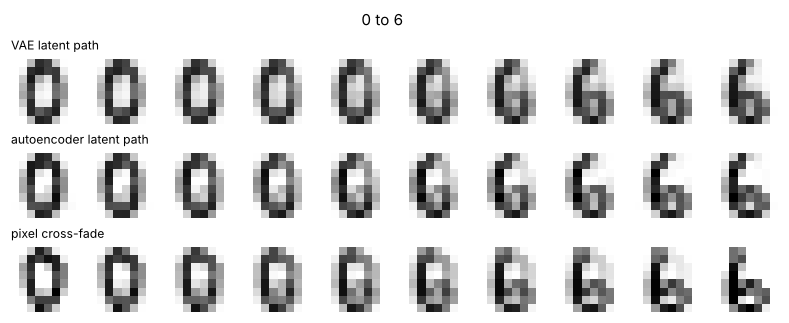

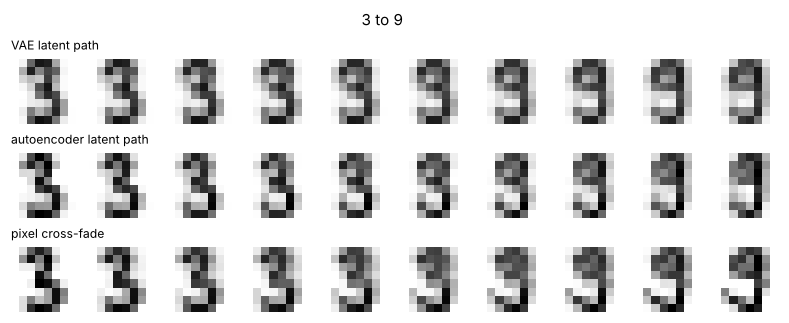

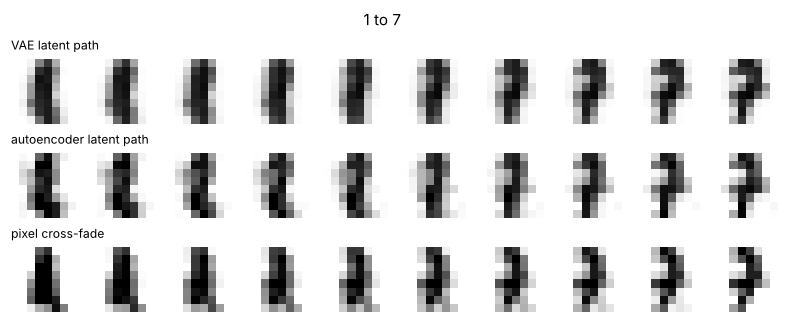

In [10]:
torch.manual_seed(0)
ae8 = AE(d_latent=8); train_ae(ae8, Xtr, epochs=300)
vae8 = VAE(d_latent=8); train_vae(vae8, Xtr, epochs=200, beta=1.0)
pairs = [(0, 6), (3, 9), (1, 7)]
for a, b in pairs:
    ia = int((yte == a).nonzero()[0]); ib = int((yte == b).nonzero()[0])
    x1, x2 = Xte[ia], Xte[ib]
    rows = [interpolate_latent(vae8, x1, x2, 10).clamp(0, 1), interpolate_latent(ae8, x1, x2, 10).clamp(0, 1), interpolate_pixels(x1, x2, 10)]
    show_rows(rows, ["VAE latent path", "autoencoder latent path", "pixel cross-fade"], title=f"{a} to {b}")

Looking at pictures is not evidence, because we tend to see what we expect. So we measure. For 40 random pairs of test digits of different classes we generate a ten-step path with
each method and record two things on the interior points: the classifier's average confidence in its top class (higher means each frame looks like some digit), and the
number of times the predicted class changes along the path (a clean transition changes once or twice, a jumpy path more).

In [11]:
def conf(s):
    with torch.no_grad():
        return torch.softmax(net(s), 1).max(1).values

def path_stats(make_path, n_pairs=40, seed=0):
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(Xte), generator=g)
    confs, changes = [], []
    k = 0
    while len(confs) < n_pairs:
        i, j = int(idx[k]), int(idx[k + 1]); k += 2
        if yte[i] == yte[j]:
            continue
        p = make_path(Xte[i], Xte[j]).clamp(0, 1)
        with torch.no_grad():
            pred = net(p).argmax(1)
        confs.append(conf(p)[1:-1].mean().item())
        changes.append(int((pred[1:] != pred[:-1]).sum()))
    return np.mean(confs), np.mean(changes)

methods = {
    "VAE latent path": lambda a, b: interpolate_latent(vae8, a, b, 10),
    "autoencoder latent path": lambda a, b: interpolate_latent(ae8, a, b, 10),
    "pixel cross-fade": lambda a, b: interpolate_pixels(a, b, 10),
}
print(f"{'method':26s} mean confidence   class changes per path")
for name, f in methods.items():
    c, ch = path_stats(f)
    print(f"{name:26s} {c:15.3f}   {ch:18.2f}")

method                     mean confidence   class changes per path
VAE latent path                      0.921                 1.50
autoencoder latent path              0.927                 1.50
pixel cross-fade                     0.924                 1.25


On this data the three methods are close, and the pixel cross-fade is not worse by either measure. That is an honest result and worth keeping: 8 by 8 digits are so
small that a blend of two of them still looks like a smudged digit, so the check cannot separate the methods. Interpolation in latent space is a
tool for exploring a learned space, and on larger, more structured images it separates from pixel blending much more clearly. It is not a guarantee, and a claim about
it needs a measurement like this one.

## 3. Moving along one latent dimension

For the 8-dimensional VAE we start at the code of one test digit and sweep a single dimension from -3 to 3, holding the others fixed. If a dimension has a
simple meaning, the picture changes in one simple way. We also count the number of pixels that change appreciably across the sweep, per dimension.

variance of each posterior mean: [0.69 0.32 0.86 0.   0.72 0.   0.   0.83]
dimension 2: pixels that change by more than 0.25 across the sweep = 34, predicted classes along the sweep = [4, 4, 4, 4, 8, 8, 3, 3, 3, 3]
dimension 7: pixels that change by more than 0.25 across the sweep = 31, predicted classes along the sweep = [6, 2, 3, 3, 3, 3, 3, 3, 3, 3]
dimension 4: pixels that change by more than 0.25 across the sweep = 29, predicted classes along the sweep = [0, 9, 9, 9, 3, 3, 3, 2, 2, 2]
dimension 0: pixels that change by more than 0.25 across the sweep = 22, predicted classes along the sweep = [2, 3, 3, 3, 3, 3, 3, 3, 3, 3]


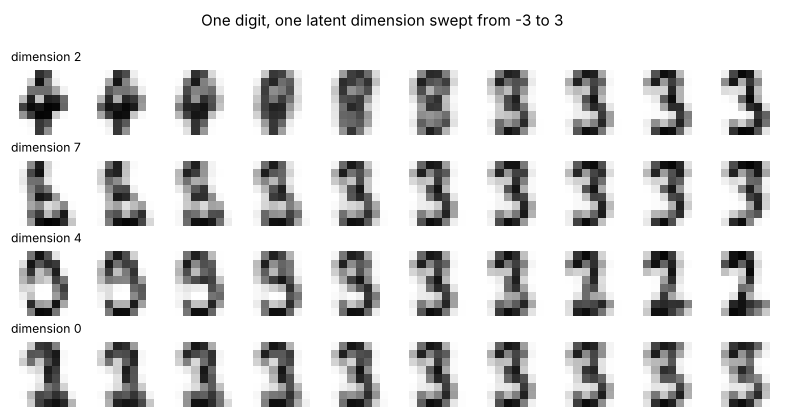

In [12]:
with torch.no_grad():
    mu_te, _ = vae8.encode(Xte)
    var_dims = mu_te.var(0)
print("variance of each posterior mean:", np.round(var_dims.numpy(), 2))
order = torch.argsort(var_dims, descending=True)[:4].tolist()
base = Xte[int((yte == 3).nonzero()[0])]
with torch.no_grad():
    z0 = vae8.encode(base[None])[0]
rows, labels = [], []
sweep = torch.linspace(-3, 3, 10)
changed = {}
for d in order:
    z = z0.repeat(10, 1); z[:, d] = sweep
    with torch.no_grad():
        imgs = torch.sigmoid(vae8.decode(z))
        pred = net(imgs).argmax(1)
    rows.append(imgs); labels.append(f"dimension {d}")
    changed[d] = (imgs.max(0).values - imgs.min(0).values > 0.25).sum().item()
    print(f"dimension {d}: pixels that change by more than 0.25 across the sweep = {changed[d]:2d}, predicted classes along the sweep = {pred.tolist()}")
show_rows(rows, labels, title="One digit, one latent dimension swept from -3 to 3")

Each of the active dimensions changes many pixels at once, and some sweeps change the digit's identity as well as its shape. The dimensions are not neat labelled
controls such as "thickness" or "slant". Nothing in the objective asks for that, and a standard VAE does not produce it. Raising $\beta$ pushes towards more independent dimensions, but it
costs reconstruction quality as Part 3 showed, and independence of the coordinates is still not the same as each one having a human-meaningful role.

## 4. Conditioning: asking for a particular digit

A conditional VAE feeds the label to both the encoder and the decoder. The code then does not need to carry the digit's identity, because the decoder is told it. To sample, draw $z$
from the prior and supply the class you want.

share of samples the classifier assigns to the requested digit, by digit:
  conditional VAE: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]  mean 1.0
class counts among 1000 samples from the unconditional VAE (no control): [104, 87, 88, 118, 84, 101, 100, 79, 147, 92]


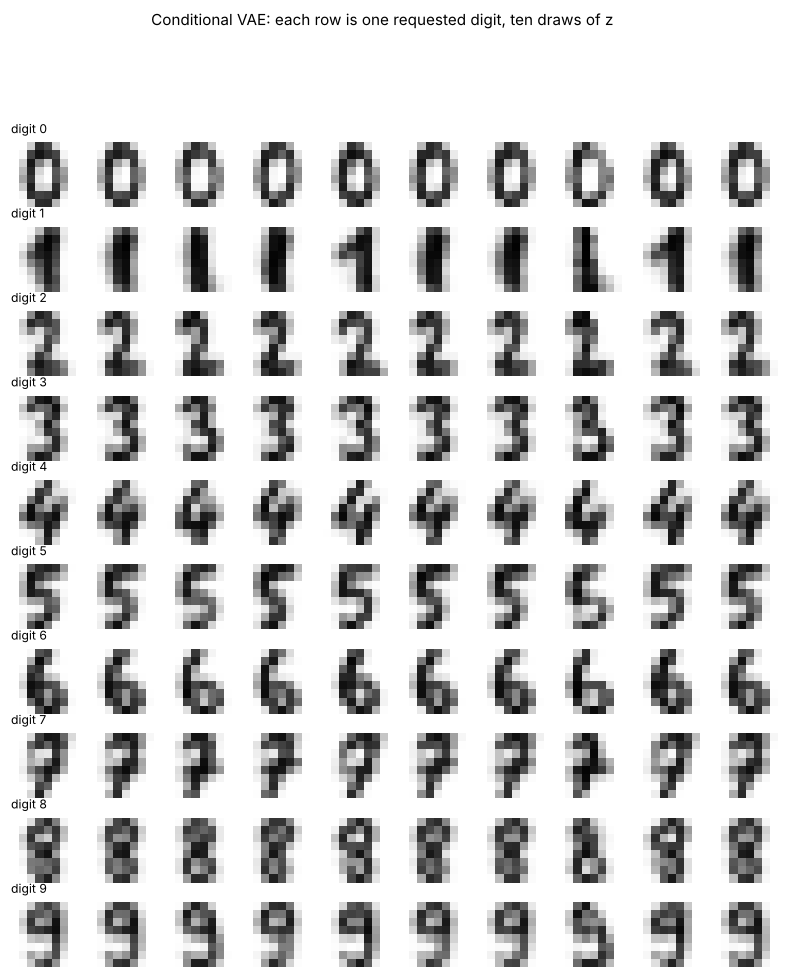

In [13]:
torch.manual_seed(0)
cvae = VAE(d_latent=4, n_classes=10); train_vae(cvae, Xtr, one_hot(ytr), epochs=200, beta=1.0)
rows, labels = [], []
accs = []
for d in range(10):
    s = sample_conditional(cvae, d, 100, seed=d)
    with torch.no_grad():
        accs.append((net(s).argmax(1) == d).float().mean().item())
print("share of samples the classifier assigns to the requested digit, by digit:")
print("  conditional VAE:", np.round(accs, 2), " mean", round(float(np.mean(accs)), 3))
with torch.no_grad():
    pred_un = net(sample_prior(vae8, 1000, seed=1)).argmax(1)
print("class counts among 1000 samples from the unconditional VAE (no control):", torch.bincount(pred_un, minlength=10).tolist())
rows = [sample_conditional(cvae, d, 10, seed=7)[:10] for d in range(10)]
show_rows(rows, [f"digit {d}" for d in range(10)], title="Conditional VAE: each row is one requested digit, ten draws of z")

Asking for a digit works: nearly every sample is classified as the requested class, whereas the unconditional VAE gives no control and a class mix you cannot steer.
There is a second experiment worth running. If the label carries the digit's identity, what does $z$ carry? We fix one draw of $z$ and change only the class.

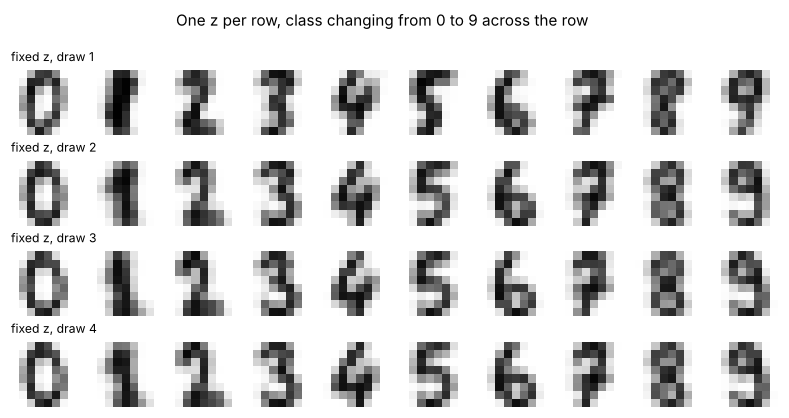

In [14]:
g = torch.Generator().manual_seed(11)
rows, labels = [], []
for r in range(4):
    z = torch.randn(1, 4, generator=g).repeat(10, 1)
    c = F.one_hot(torch.arange(10), 10).float()
    with torch.no_grad():
        rows.append(torch.sigmoid(cvae.decode(z, c)))
    labels.append(f"fixed z, draw {r + 1}")
show_rows(rows, labels, title="One z per row, class changing from 0 to 9 across the row")

Along a row the digit changes while its style (how thick, how slanted, how large) stays similar, and down the rows the style changes. The label has taken over the
identity of the digit, and the code is left to describe what the label does not: the style. This split is the reason conditioning is the standard way to put a
control on a generative model.

## What to take away

- A VAE's latent space is centred and scaled like its prior, so you can sample from it and walk around in it. An autoencoder's is not.
- Whether a latent path beats a pixel blend depends on the data, and the check on these small digits does not separate them. Measure before claiming.
- A plain VAE's latent dimensions are not neat controls. Conditioning gives you the control you want, and leaves the code to describe the rest.